In [1]:
!pip install pandas numpy matplotlib seaborn scipy scikit-learn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Upload the Excel workbook when running in Google Colab.
# If running locally, set file_path to the location of your Excel file.

try:
    from google.colab import files
    uploaded = files.upload()
    file_path = next(iter(uploaded))
except ImportError:
    file_path = "TSDK_South Africa.xlsx"

df = pd.read_excel(file_path, sheet_name="Data")
print("Loaded file:", file_path)
print("Dataset shape:", df.shape)

Saving TSDK_South Africa.xlsx to TSDK_South Africa (1).xlsx
Loaded file: TSDK_South Africa (1).xlsx
Dataset shape: (72, 46)


In [4]:
df.head()

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Africa,South Africa,ZA,ZAF,710,Population,All,..,..,..,...,52.832659,53.687125,54.544184,55.386369,56.207649,57.009751,57.792520,58.558267,59.308690,60.041996
1,Africa,South Africa,ZA,ZAF,710,Population,Urban,..,..,..,...,63.272000,63.793000,64.312000,64.828000,65.341000,65.850000,66.355000,66.856000,67.354000,67.847000
2,Africa,South Africa,ZA,ZAF,710,Population,Rural,..,..,..,...,36.728000,36.207000,35.688000,35.172000,34.659000,34.150000,33.645000,33.144000,32.646000,32.153000
3,Africa,South Africa,ZA,ZAF,710,Population growth,All,..,..,..,...,1.581354,1.604367,1.583787,1.532243,1.471933,1.416947,1.363703,1.316292,1.273356,1.228841
4,Africa,South Africa,ZA,ZAF,710,GDP,All,..,..,..,...,329233.094599,337416.077838,342186.555601,346709.790459,349013.858373,353055.253707,358307.364997,358712.444718,335640.150576,352135.530347


Understand the dataset


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 72
Columns: 46


In [6]:
df.columns.tolist()

['Continent',
 'Country name',
 'ISO Alpha-2 code',
 'ISO Alpha-3 code',
 'Numeric country code',
 'Variable',
 'Type',
 'Sub-type',
 'Fuel',
 'Destination',
 'Data code',
 'Unit',
 'Citation',
 'Notes',
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014,
 2015,
 2016,
 2017,
 2018,
 2019,
 2020,
 2021]

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 46 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Continent             72 non-null     object 
 1   Country name          72 non-null     object 
 2   ISO Alpha-2 code      72 non-null     object 
 3   ISO Alpha-3 code      72 non-null     object 
 4   Numeric country code  72 non-null     int64  
 5   Variable              72 non-null     object 
 6   Type                  72 non-null     object 
 7   Sub-type              72 non-null     object 
 8   Fuel                  72 non-null     object 
 9   Destination           72 non-null     object 
 10  Data code             72 non-null     object 
 11  Unit                  72 non-null     object 
 12  Citation              69 non-null     object 
 13  Notes                 72 non-null     object 
 14  1990                  16 non-null     float64
 15  1991                  16 

In [8]:
display(df.head())
display(df.tail())

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Africa,South Africa,ZA,ZAF,710,Population,All,..,..,..,...,52.832659,53.687125,54.544184,55.386369,56.207649,57.009751,57.792520,58.558267,59.308690,60.041996
1,Africa,South Africa,ZA,ZAF,710,Population,Urban,..,..,..,...,63.272000,63.793000,64.312000,64.828000,65.341000,65.850000,66.355000,66.856000,67.354000,67.847000
2,Africa,South Africa,ZA,ZAF,710,Population,Rural,..,..,..,...,36.728000,36.207000,35.688000,35.172000,34.659000,34.150000,33.645000,33.144000,32.646000,32.153000
3,Africa,South Africa,ZA,ZAF,710,Population growth,All,..,..,..,...,1.581354,1.604367,1.583787,1.532243,1.471933,1.416947,1.363703,1.316292,1.273356,1.228841
4,Africa,South Africa,ZA,ZAF,710,GDP,All,..,..,..,...,329233.094599,337416.077838,342186.555601,346709.790459,349013.858373,353055.253707,358307.364997,358712.444718,335640.150576,352135.530347


,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
67,Africa,South Africa,ZA,ZAF,710,Load factor,Road,Car,Hybrid,Urban,...,NaN,1.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
68,Africa,South Africa,ZA,ZAF,710,Load factor,Road,Car,Petrol,Urban,...,NaN,1.4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
69,Africa,South Africa,ZA,ZAF,710,Load factor,Road,Minibus,All,Urban,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
70,Africa,South Africa,ZA,ZAF,710,Load factor,Road,Minibus,Petrol,Urban,...,NaN,7.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
71,Africa,South Africa,ZA,ZAF,710,Load factor,Road,Bus,Diesel,Urban,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Data cleaning


Make a copy

In [9]:
df_clean = df.copy()

Check missing values

In [10]:
df_clean.isnull().sum()

,0
Continent,0
Country name,0
ISO Alpha-2 code,0
ISO Alpha-3 code,0
Numeric country code,0
Variable,0
Type,0
Sub-type,0
Fuel,0
Destination,0


Visualise missing values

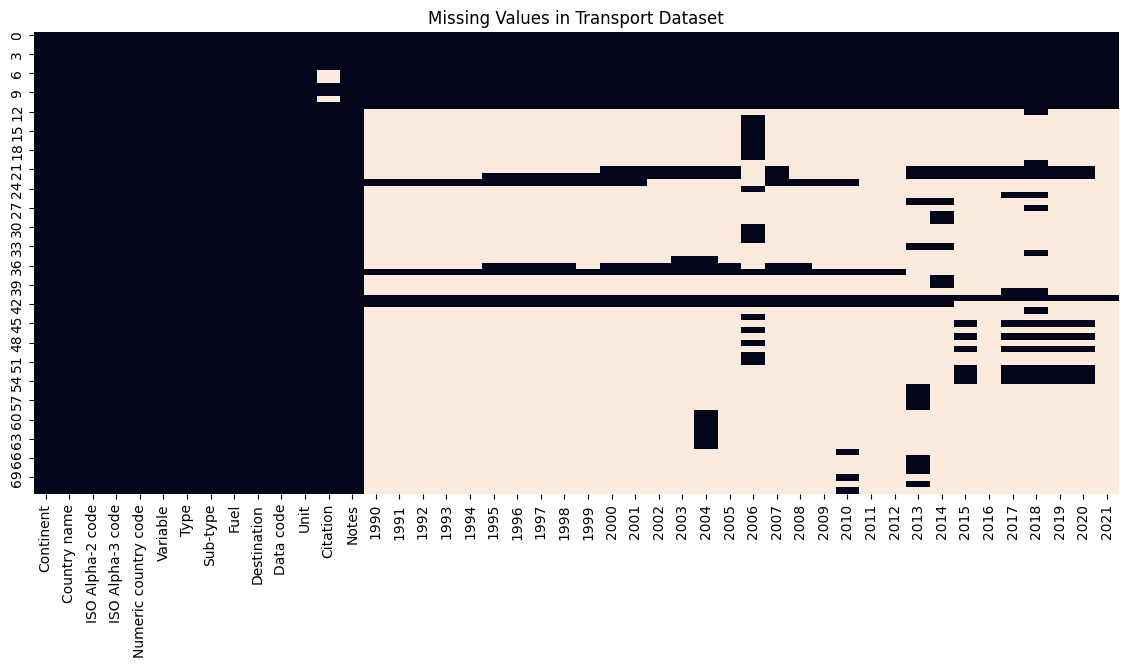

In [11]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False
)

plt.title("Missing Values in Transport Dataset")
plt.show()

Check duplicate records

In [12]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


Identify missing-value symbols

In [13]:
df_clean = df_clean.replace(
    ["..", "...", "N/A", "n/a", ""],
    np.nan
)

Convert year columns to numeric

In [14]:
year_columns = [
    col for col in df_clean.columns
    if str(col).isdigit()
    and 1990 <= int(col) <= 2021
]

for col in year_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Year columns:", year_columns)

Year columns: [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]


Check missing values again

In [15]:
df_clean.isnull().sum()

,0
Continent,0
Country name,0
ISO Alpha-2 code,0
ISO Alpha-3 code,0
Numeric country code,0
Variable,0
Type,0
Sub-type,12
Fuel,12
Destination,12


Transform the dataset

In [16]:
id_columns = [
    col for col in df_clean.columns
    if col not in year_columns
]

df_long = df_clean.melt(
    id_vars=id_columns,
    value_vars=year_columns,
    var_name="Year",
    value_name="Value"
)

df_long["Year"] = pd.to_numeric(
    df_long["Year"],
    errors="coerce"
)

df_long["Value"] = pd.to_numeric(
    df_long["Value"],
    errors="coerce"
)

df_long.head()

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,Data code,Unit,Citation,Notes,Year,Value
0,Africa,South Africa,ZA,ZAF,710,Population,All,NaN,NaN,NaN,POP_TOT,million people,The World Bank (2022). World Development Indic...,A,1990,36.800507
1,Africa,South Africa,ZA,ZAF,710,Population,Urban,NaN,NaN,NaN,POP_URB,%,The World Bank (2022). World Development Indic...,A,1990,52.037000
2,Africa,South Africa,ZA,ZAF,710,Population,Rural,NaN,NaN,NaN,POP_RUR,%,The World Bank (2022). World Development Indic...,A,1990,47.963000
3,Africa,South Africa,ZA,ZAF,710,Population growth,All,NaN,NaN,NaN,POP_GRO,%,The World Bank (2022). World Development Indic...,A,1990,2.393746
4,Africa,South Africa,ZA,ZAF,710,GDP,All,NaN,NaN,NaN,GDP_TOT,million USD (2015),The World Bank (2022). World Development Indic...,A,1990,185160.422892


Check the transformed dataset

In [17]:
print(df_long.shape)

df_long.info()

df_long.head(10)

(2304, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2304 entries, 0 to 2303
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Continent             2304 non-null   object 
 1   Country name          2304 non-null   object 
 2   ISO Alpha-2 code      2304 non-null   object 
 3   ISO Alpha-3 code      2304 non-null   object 
 4   Numeric country code  2304 non-null   int64  
 5   Variable              2304 non-null   object 
 6   Type                  2304 non-null   object 
 7   Sub-type              1920 non-null   object 
 8   Fuel                  1920 non-null   object 
 9   Destination           1920 non-null   object 
 10  Data code             2304 non-null   object 
 11  Unit                  2304 non-null   object 
 12  Citation              2208 non-null   object 
 13  Notes                 2304 non-null   object 
 14  Year                  2304 non-null   int64  
 15  Value     

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,Data code,Unit,Citation,Notes,Year,Value
0,Africa,South Africa,ZA,ZAF,710,Population,All,NaN,NaN,NaN,POP_TOT,million people,The World Bank (2022). World Development Indic...,A,1990,36.800507
1,Africa,South Africa,ZA,ZAF,710,Population,Urban,NaN,NaN,NaN,POP_URB,%,The World Bank (2022). World Development Indic...,A,1990,52.037000
2,Africa,South Africa,ZA,ZAF,710,Population,Rural,NaN,NaN,NaN,POP_RUR,%,The World Bank (2022). World Development Indic...,A,1990,47.963000
3,Africa,South Africa,ZA,ZAF,710,Population growth,All,NaN,NaN,NaN,POP_GRO,%,The World Bank (2022). World Development Indic...,A,1990,2.393746
4,Africa,South Africa,ZA,ZAF,710,GDP,All,NaN,NaN,NaN,GDP_TOT,million USD (2015),The World Bank (2022). World Development Indic...,A,1990,185160.422892
5,Africa,South Africa,ZA,ZAF,710,GDP,Agriculture,NaN,NaN,NaN,GDP_AGR,%,The World Bank (2022). World Development Indic...,A,1990,3.777056
6,Africa,South Africa,ZA,ZAF,710,GDP,Construction,NaN,NaN,NaN,GDP_CON,%,NaN,E,1990,6.680117
7,Africa,South Africa,ZA,ZAF,710,GDP,Mining,NaN,NaN,NaN,GDP_MIN,%,NaN,E,1990,6.680117
8,Africa,South Africa,ZA,ZAF,710,GDP,Manufacturing,NaN,NaN,NaN,GDP_MAN,%,The World Bank (2022). World Development Indic...,A,1990,23.743511
9,Africa,South Africa,ZA,ZAF,710,GDP,Service,NaN,NaN,NaN,GDP_SER,%,The World Bank (2022). World Development Indic...,A,1990,52.439080


In [18]:
# Check how much usable data is available for each indicator.
coverage = (
    df_long.dropna(subset=["Value"])
    .groupby(["Variable", "Unit"], dropna=False)
    .agg(
        Available_Records=("Value", "count"),
        First_Year=("Year", "min"),
        Last_Year=("Year", "max")
    )
    .reset_index()
    .sort_values("Variable")
)

display(coverage)

,Variable,Unit,Available_Records,First_Year,Last_Year
0,Energy intensity,MJ/passenger-km,4,2013,2013
1,Energy intensity,MJ/vehicle-km,6,2004,2004
2,Freight activity,milion ton-km,110,1990,2021
3,GDP,%,192,1990,2021
4,GDP,million USD (2015),32,1990,2021
5,GDP growth,%,32,1990,2021
6,Load factor,passenger/vehicle,7,2010,2013
7,Passenger activity,million passenger-km,63,1990,2020
8,Population,%,64,1990,2021
9,Population,million people,32,1990,2021


Exploratory Data Analysis (EDA)

Identify available indicators

In [19]:
df_long["Variable"].value_counts()

,count
Variable,
Freight activity,576
Passenger activity,448
Vehicle stock,352
Energy intensity,320
GDP,224
Load factor,224
Population,96
GDP growth,32
Population growth,32


Identify transport modes

In [20]:
df_long["Type"].value_counts()

,count
Type,
Road,1312
Rail,416
Aviation,160
All,128
Urban,32
Construction,32
Agriculture,32
Rural,32
Mining,32


Explore the available years

In [21]:
df_long["Year"].describe()

,Year
count,2304.000000
mean,2005.500000
std,9.235097
min,1990.000000
25%,1997.750000
50%,2005.500000
75%,2013.250000
max,2021.000000


Analyse population over time

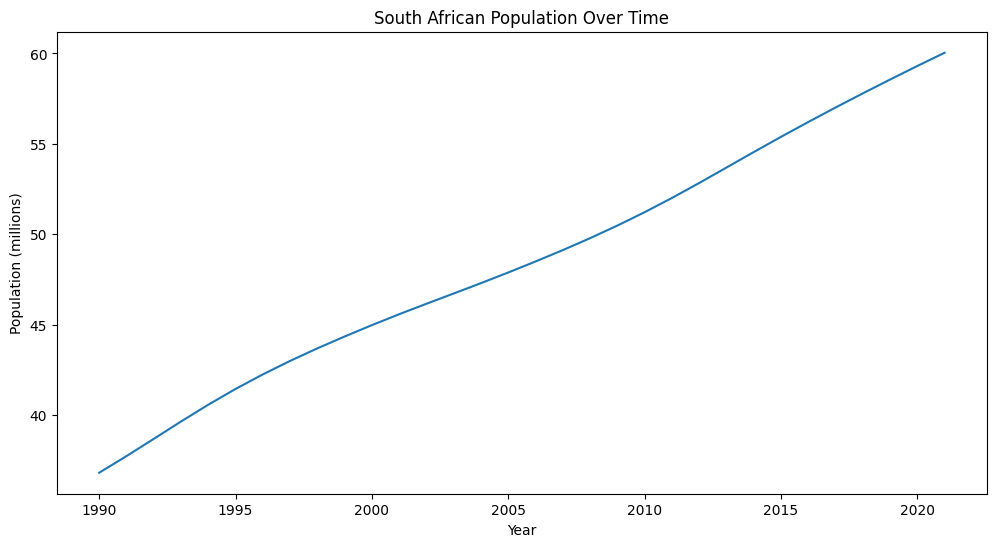

In [22]:
population = df_long[
    df_long["Variable"] == "Population"
]

population_total = population[
    population["Type"] == "All"
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=population_total,
    x="Year",
    y="Value"
)

plt.title("South African Population Over Time")
plt.xlabel("Year")
plt.ylabel("Population (millions)")

plt.show()

Analyse GDP over time

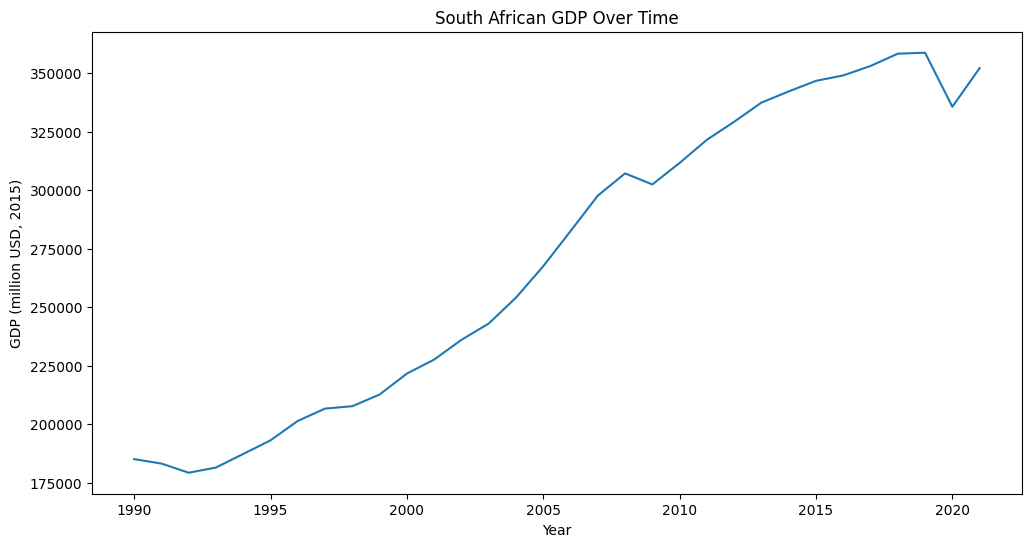

In [23]:
gdp = df_long[
    (df_long["Variable"] == "GDP") &
    (df_long["Type"] == "All")
]

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=gdp,
    x="Year",
    y="Value"
)

plt.title("South African GDP Over Time")
plt.xlabel("Year")
plt.ylabel("GDP (million USD, 2015)")

plt.show()

Analyse transport activity

passenger transport

In [24]:
passenger = df_long[
    df_long["Variable"] == "Passenger activity"
]

display(passenger.head())

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,Data code,Unit,Citation,Notes,Year,Value
12,Africa,South Africa,ZA,ZAF,710,Passenger activity,Road,All,All,All,ROAD_PA_MOV,million passenger-km,UN DESA (2020). Indicator 9.1.2: Passenger vol...,I,1990,NaN
13,Africa,South Africa,ZA,ZAF,710,Passenger activity,Road,Motorcycle,All,All,ROAD_PA_MOTORC,million passenger-km,"Merven, B., Stone, A., Hughes, A. and Cohen, B...",I,1990,NaN
14,Africa,South Africa,ZA,ZAF,710,Passenger activity,Road,Car,All,All,ROAD_PA_CAR,million passenger-km,"Merven, B., Stone, A., Hughes, A. and Cohen, B...",I,1990,NaN
15,Africa,South Africa,ZA,ZAF,710,Passenger activity,Road,Minibus,All,All,ROAD_PA_MINIBU,million passenger-km,"Merven, B., Stone, A., Hughes, A. and Cohen, B...",I,1990,NaN
16,Africa,South Africa,ZA,ZAF,710,Passenger activity,Road,Bus,All,All,ROAD_PA_BUS,million passenger-km,"Merven, B., Stone, A., Hughes, A. and Cohen, B...",I,1990,NaN


investigate freight

In [25]:
freight = df_long[
    df_long["Variable"] == "Freight activity"
]

display(freight.head())

,Continent,Country name,ISO Alpha-2 code,ISO Alpha-3 code,Numeric country code,Variable,Type,Sub-type,Fuel,Destination,Data code,Unit,Citation,Notes,Year,Value
26,Africa,South Africa,ZA,ZAF,710,Freight activity,Road,All,All,All,ROAD_GO_NAT,milion ton-km,"Havenga, J.H., Simpson, Z.P., King, D. de Bod,...",A,1990,NaN
27,Africa,South Africa,ZA,ZAF,710,Freight activity,Road,All,All,All,ROAD_GO_NAT,milion ton-km,UN DESA (2020). Indicator 9.1.2: Freight volum...,I,1990,NaN
28,Africa,South Africa,ZA,ZAF,710,Freight activity,Road,All,All,Urban,ROAD_GO_URB,milion ton-km,"Havenga, J.H., Simpson, Z.P., King, D. de Bod,...",A,1990,NaN
29,Africa,South Africa,ZA,ZAF,710,Freight activity,Road,All,All,Rural,ROAD_GO_RUR,milion ton-km,"Havenga, J.H., Simpson, Z.P., King, D. de Bod,...",A,1990,NaN
30,Africa,South Africa,ZA,ZAF,710,Freight activity,Road,Light-duty vehicle,All,All,ROAD_GO_LDV,milion ton-km,"Merven, B., Stone, A., Hughes, A. and Cohen, B...",I,1990,NaN


Statistical analysis

Correlation analysis

In [26]:
# Compare total population with total GDP.
# Filtering Type == "All" avoids mixing totals with urban/rural or sector rows.
analysis_data = df_long[
    (df_long["Variable"].isin(["Population", "GDP"])) &
    (df_long["Type"] == "All")
]

display(
    analysis_data[
        ["Variable", "Type", "Year", "Value", "Unit"]
    ].head()
)

,Variable,Type,Year,Value,Unit
0,Population,All,1990,36.800507,million people
4,GDP,All,1990,185160.422892,million USD (2015)
72,Population,All,1991,37.718952,million people
76,GDP,All,1991,183275.036204,million USD (2015)
144,Population,All,1992,38.672611,million people


table with one column per variable

In [27]:
correlation_data = analysis_data.pivot_table(
    index="Year",
    columns="Variable",
    values="Value",
    aggfunc="first"
)

correlation_data.head()

Variable,GDP,Population
Year,,
1990,185160.422892,36.800507
1991,183275.036204,37.718952
1992,179358.388483,38.672611
1993,181570.878123,39.633754
1994,187381.146228,40.564061


Calculate correlation

In [28]:
correlation_data.corr()

Variable,GDP,Population
Variable,,
GDP,1.000000,0.970054
Population,0.970054,1.000000


Visualise

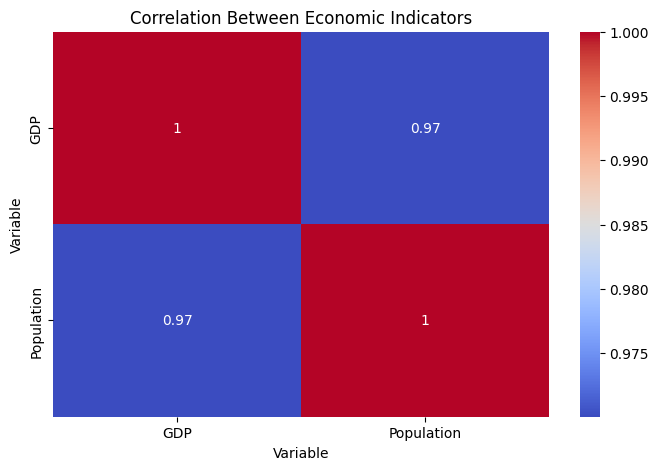

In [29]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_data.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Economic Indicators")

plt.show()

Year-to-year changes

In [30]:
correlation_data["GDP_Change"] = (
    correlation_data["GDP"].pct_change() * 100
)

correlation_data.head()

Variable,GDP,Population,GDP_Change
Year,,,
1990,185160.422892,36.800507,NaN
1991,183275.036204,37.718952,-1.018245
1992,179358.388483,38.672611,-2.137033
1993,181570.878123,39.633754,1.233558
1994,187381.146228,40.564061,3.200000


Findings and interpretation

## Findings and Interpretation

Use only results produced by the executed analysis. Distinguish observed values from modelled estimates and do not treat missing years as zero.

### Finding 1
[Insert a finding supported by the analysis.]

### Finding 2
[Insert a finding supported by the analysis.]

### Finding 3
[Insert a finding supported by the analysis.]

## Recommendations

[Develop recommendations based on the evidence. Explain which data supports each recommendation.]

Limitations

## Limitations

- Some transport indicators have limited historical coverage.
- Certain values are modelled estimates rather than direct observations.
- Different indicators may originate from different sources.
- Some data is outdated.
- The dataset does not provide detailed company-level financial information.
- Correlation does not establish causation.

Conclusion

## Conclusion

This project analysed historical South African transport data
using Python and statistical analysis.

The findings provide insights into historical transport activity,
economic trends and potential sustainability opportunities.

Further research could investigate additional transport data
and develop more detailed predictive models.